In [2]:
import pandas as pd
import numpy as np

df = pd.read_excel('/Users/rogertraj/Desktop/summer computational neuro/module 2/eeg_32ch_dataset.xlsx')

# 6.1 - Task 1: Check for missing variables
print("Missing values per column:")
print(df.isnull().sum())
print(f"\nTotal missing values: {df.isnull().sum().sum()}")

# Task 2: Identify channels with unusually high voltages
media_voltaje = df['MeanVoltage_uV'].mean()
std_voltaje = df['MeanVoltage_uV'].std()
umbral_alto = media_voltaje + 2*std_voltaje  # 2 desviaciones estandar

canales_altos = df[df['MeanVoltage_uV'] > umbral_alto]
print(f"\nChannels with unusually high voltage (> mean + 2*std = {umbral_alto:.2f}):")
print(canales_altos[['Channel', 'Region', 'MeanVoltage_uV', 'Condition']])

# 6.1 - Task 3: Standardize the power variables
columnas_a_estandarizar = ['DeltaPower', 'ThetaPower', 'AlphaPower', 'BetaPower', 'GammaPower', 'Entropy']

for col in columnas_a_estandarizar:
    df[col + '_z'] = (df[col] - df[col].mean()) / df[col].std()

print("\nStandardized columns added (mean ~0, std ~1):")
print(df[[c + '_z' for c in columnas_a_estandarizar]].agg(['mean', 'std']))

Missing values per column:
Channel           0
Region            0
MeanVoltage_uV    0
DeltaPower        0
ThetaPower        0
AlphaPower        0
BetaPower         0
GammaPower        0
Entropy           0
Condition         0
dtype: int64

Total missing values: 0

Channels with unusually high voltage (> mean + 2*std = 5.64):
   Channel   Region  MeanVoltage_uV Condition
34      F3  Frontal            5.94      Task

Standardized columns added (mean ~0, std ~1):
      DeltaPower_z  ThetaPower_z  AlphaPower_z   BetaPower_z  GammaPower_z  \
mean -5.516421e-16 -3.851086e-16  7.216450e-16  2.602085e-16  2.532696e-16   
std   1.000000e+00  1.000000e+00  1.000000e+00  1.000000e+00  1.000000e+00   

         Entropy_z  
mean -5.065393e-16  
std   1.000000e+00  


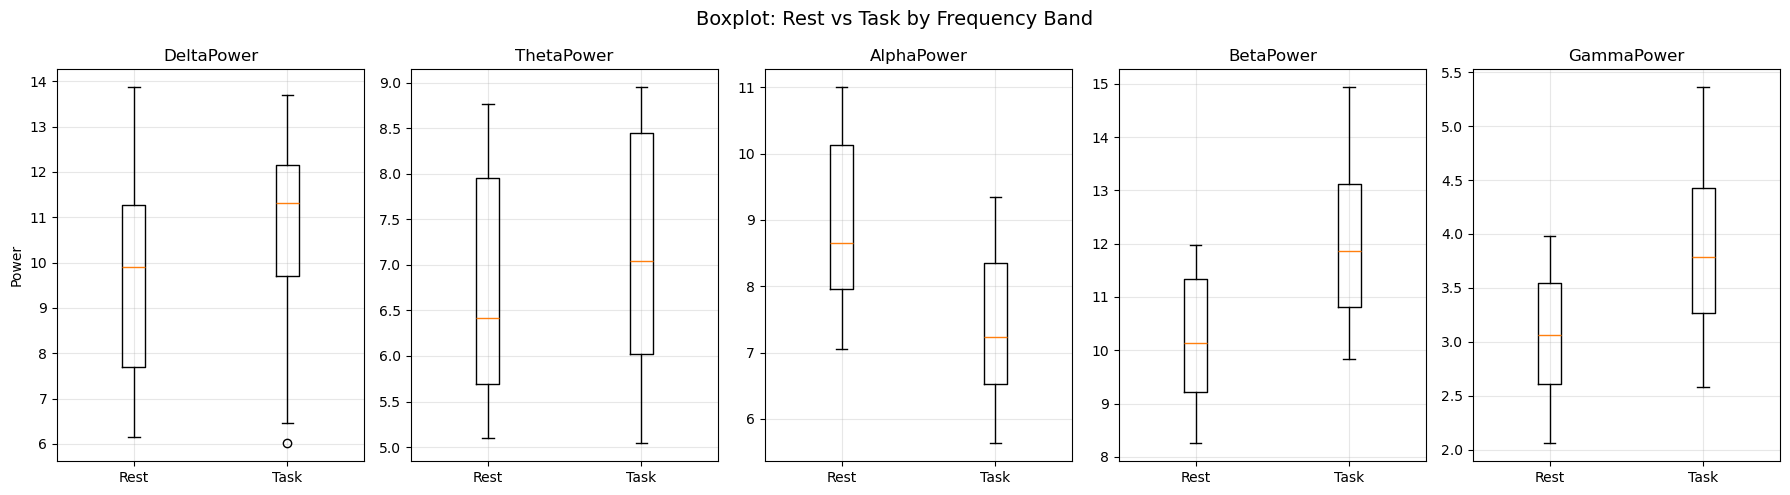

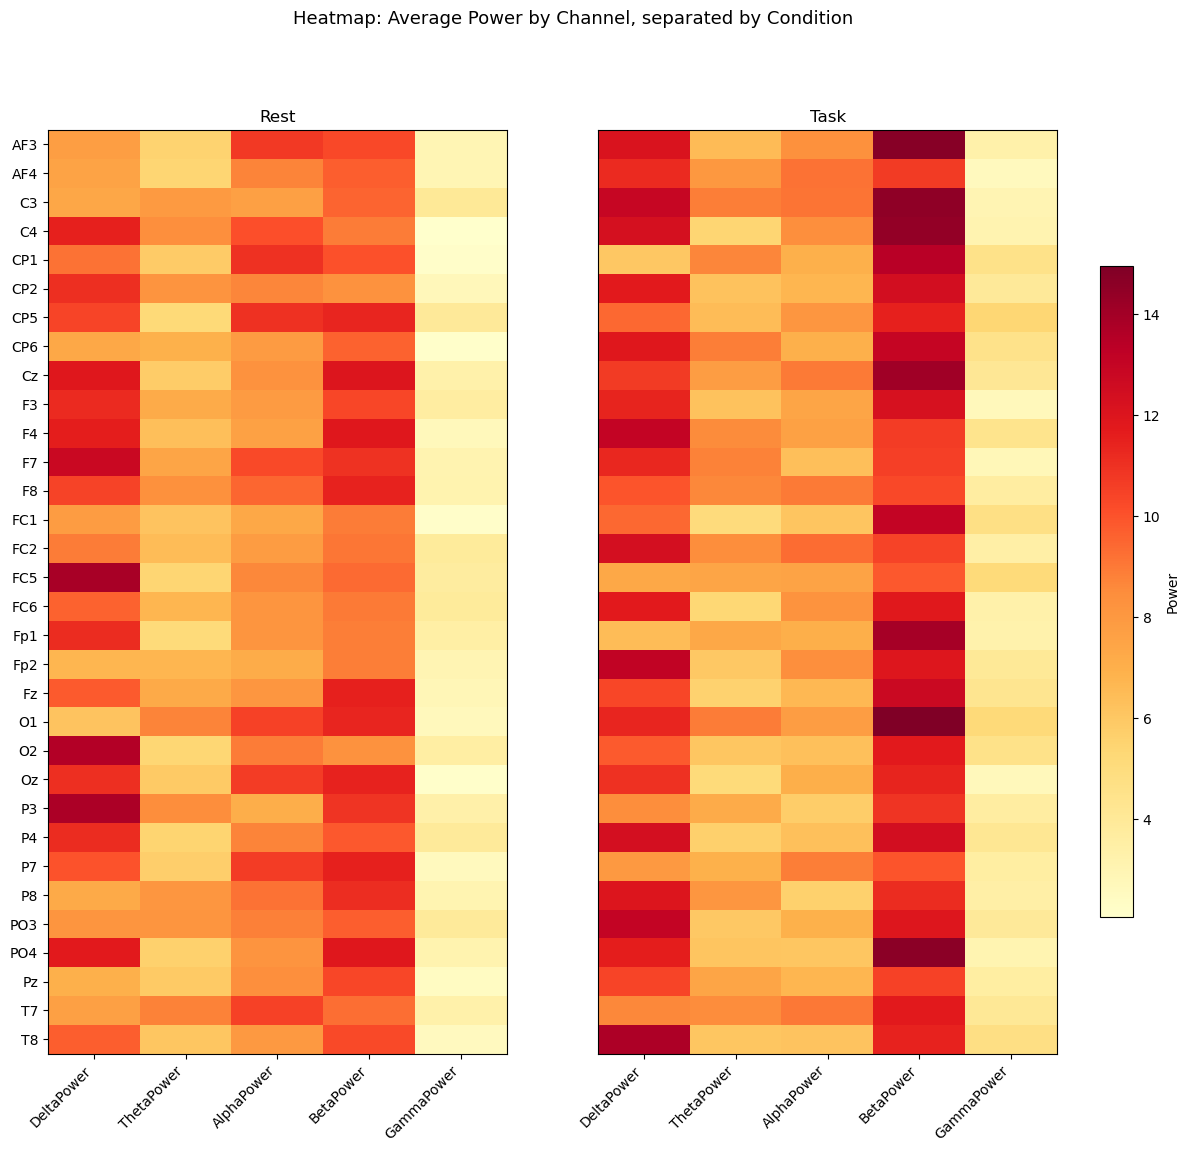

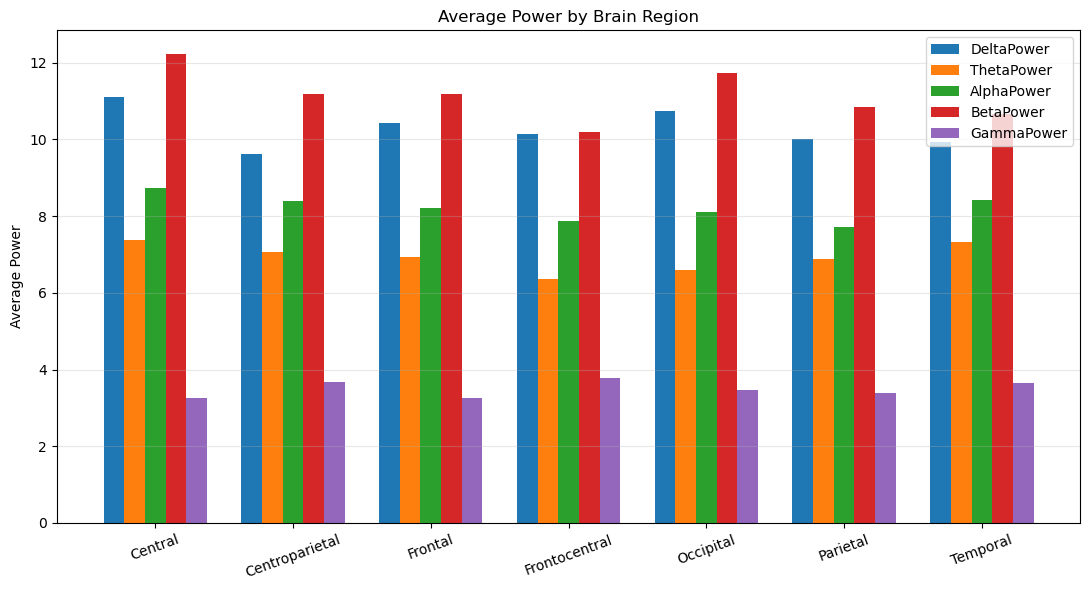

In [7]:
import matplotlib.pyplot as plt

# 6.2: Exploratory Statistics

bandas = ['DeltaPower', 'ThetaPower', 'AlphaPower', 'BetaPower', 'GammaPower']

# 1. Boxplot: Rest vs Task for each frequency band
fig, axes = plt.subplots(1, 5, figsize=(18, 5), sharey=False)
for i, banda in enumerate(bandas):
    data_rest = df[df['Condition']=='Rest'][banda]
    data_task = df[df['Condition']=='Task'][banda]
    axes[i].boxplot([data_rest, data_task], tick_labels=['Rest', 'Task'])
    axes[i].set_title(banda)
    axes[i].grid(alpha=0.3)
axes[0].set_ylabel("Power")
plt.suptitle("Boxplot: Rest vs Task by Frequency Band", fontsize=14)
plt.tight_layout()
plt.show()

# 2. Heatmap: average power by channel
heatmap_rest = df[df['Condition']=='Rest'].groupby('Channel')[power_vars].mean()
heatmap_task = df[df['Condition']=='Task'].groupby('Channel')[power_vars].mean()
heatmap_task = heatmap_task.loc[heatmap_rest.index]  # mismo orden de canales

vmin = min(heatmap_rest.values.min(), heatmap_task.values.min())
vmax = max(heatmap_rest.values.max(), heatmap_task.values.max())

fig, axes = plt.subplots(1, 2, figsize=(14, 12))

im0 = axes[0].imshow(heatmap_rest.values, aspect='auto', cmap='YlOrRd', vmin=vmin, vmax=vmax)
axes[0].set_xticks(range(len(power_vars)))
axes[0].set_xticklabels(power_vars, rotation=45, ha='right')
axes[0].set_yticks(range(len(heatmap_rest.index)))
axes[0].set_yticklabels(heatmap_rest.index)
axes[0].set_title("Rest")

im1 = axes[1].imshow(heatmap_task.values, aspect='auto', cmap='YlOrRd', vmin=vmin, vmax=vmax)
axes[1].set_xticks(range(len(power_vars)))
axes[1].set_xticklabels(power_vars, rotation=45, ha='right')
axes[1].set_yticks([])
axes[1].set_title("Task")

fig.colorbar(im1, ax=axes, label='Power', fraction=0.03, pad=0.04)
plt.suptitle("Heatmap: Average Power by Channel, separated by Condition", fontsize=13)
plt.show()


# 3. Barplot: average power by brain region
region_means = df.groupby('Region')[power_vars].mean()

fig, ax = plt.subplots(figsize=(11, 6))
x = np.arange(len(region_means.index))
width = 0.15
for i, banda in enumerate(power_vars):
    ax.bar(x + i*width, region_means[banda], width, label=banda)
ax.set_xticks(x + width*2)
ax.set_xticklabels(region_means.index, rotation=20)
ax.set_ylabel("Average Power")
ax.set_title("Average Power by Brain Region")
ax.legend()
ax.grid(alpha=0.3, axis='y')
plt.tight_layout()
plt.show()

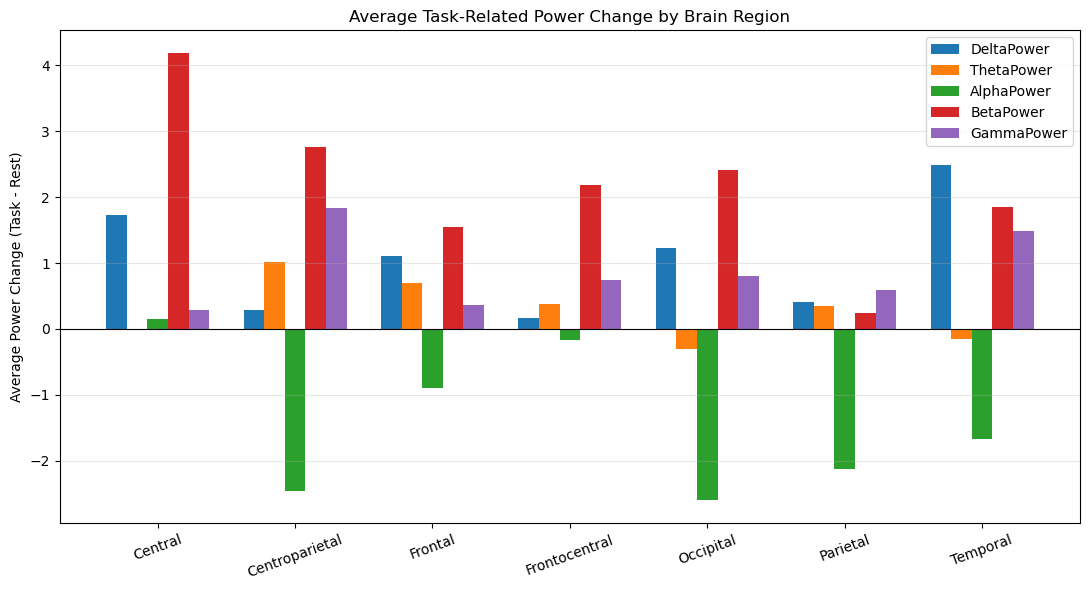

In [13]:
# Barplot: average task-related power change by region

# Paso 1: separamos Rest y Task, indexando por Channel para poder restar canal por canal
rest_data = df[df['Condition']=='Rest'].set_index('Channel')[power_vars + ['Region']]
task_data = df[df['Condition']=='Task'].set_index('Channel')[power_vars]
task_data = task_data.loc[rest_data.index]  # mismo orden de canales

# Paso 2: cambio (Task - Rest) canal por canal
cambio_por_canal = task_data[power_vars] - rest_data[power_vars]
cambio_por_canal['Region'] = rest_data['Region']

# Paso 3: promediamos ese cambio, agrupando por region
cambio_promedio_por_region = cambio_por_canal.groupby('Region')[power_vars].mean()

# Paso 4: graficamos
fig, ax = plt.subplots(figsize=(11, 6))
x = np.arange(len(cambio_promedio_por_region.index))
width = 0.15
for i, banda in enumerate(power_vars):
    ax.bar(x + i*width, cambio_promedio_por_region[banda], width, label=banda)

ax.axhline(0, color='black', linewidth=0.8)
ax.set_xticks(x + width*2)
ax.set_xticklabels(cambio_promedio_por_region.index, rotation=20)
ax.set_ylabel("Average Power Change (Task - Rest)")
ax.set_title("Average Task-Related Power Change by Brain Region")
ax.legend()
ax.grid(alpha=0.3, axis='y')
plt.tight_layout()
plt.show()

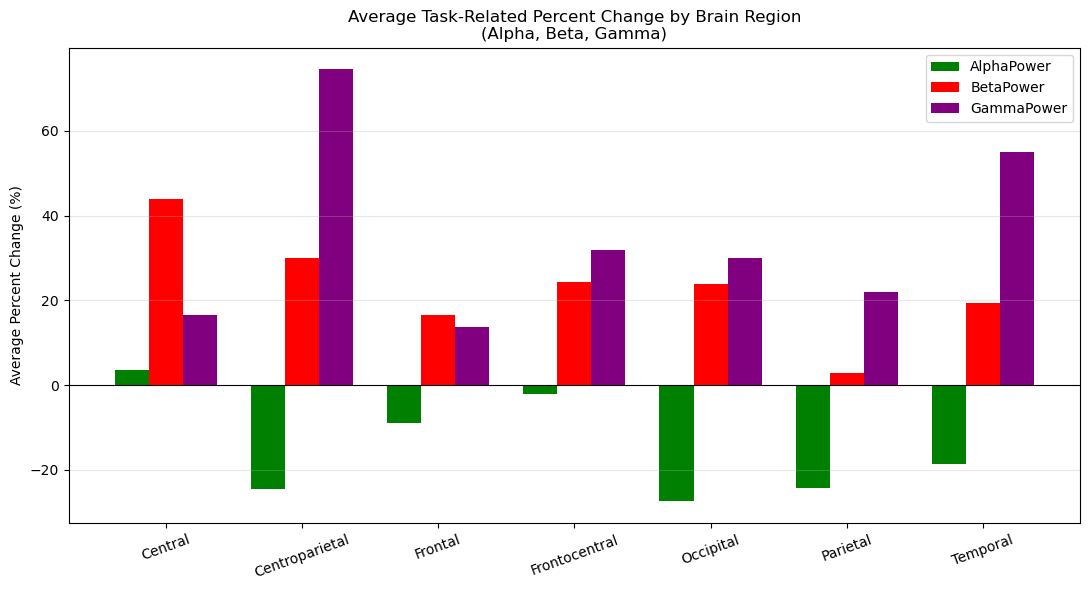

In [14]:
# Barplot: average task-related PERCENT change by region (Alpha, Beta, Gamma)

relevant_bands = ['AlphaPower', 'BetaPower', 'GammaPower']

rest_data = df[df['Condition']=='Rest'].set_index('Channel')[relevant_bands + ['Region']]
task_data = df[df['Condition']=='Task'].set_index('Channel')[relevant_bands]
task_data = task_data.loc[rest_data.index]

pct_change_per_channel = ((task_data[relevant_bands] - rest_data[relevant_bands]) / rest_data[relevant_bands]) * 100
pct_change_per_channel['Region'] = rest_data['Region']
pct_change_by_region = pct_change_per_channel.groupby('Region')[relevant_bands].mean()

fig, ax = plt.subplots(figsize=(11, 6))
x = np.arange(len(pct_change_by_region.index))
width = 0.25
colors = ['green', 'red', 'purple']
for i, band in enumerate(relevant_bands):
    ax.bar(x + i*width, pct_change_by_region[band], width, label=band, color=colors[i])

ax.axhline(0, color='black', linewidth=0.8)
ax.set_xticks(x + width)
ax.set_xticklabels(pct_change_by_region.index, rotation=20)
ax.set_ylabel("Average Percent Change (%)")
ax.set_title("Average Task-Related Percent Change by Brain Region\n(Alpha, Beta, Gamma)")
ax.legend()
ax.grid(alpha=0.3, axis='y')
plt.tight_layout()
plt.show()


In [15]:
# Sum of absolute percent change by region, to identify the strongest task-related region
sum_abs_pct_change = pct_change_by_region.abs().sum(axis=1).sort_values(ascending=False)
print("Sum of |percent change| by region (sorted):")
print(sum_abs_pct_change.round(1))

print(f"\nStrongest region: {sum_abs_pct_change.index[0]} (sum = {sum_abs_pct_change.iloc[0]:.1f}%)")

Sum of |percent change| by region (sorted):
Region
Centroparietal    129.0
Temporal           92.9
Occipital          81.2
Central            64.0
Frontocentral      58.2
Parietal           49.1
Frontal            39.4
dtype: float64

Strongest region: Centroparietal (sum = 129.0%)


In [16]:
# Sum of absolute change (not percent) by region, for Alpha, Beta, Gamma only
abs_change_per_channel = task_data[relevant_bands] - rest_data[relevant_bands]
abs_change_per_channel['Region'] = rest_data['Region']
abs_change_by_region = abs_change_per_channel.groupby('Region')[relevant_bands].mean()

sum_abs_change = abs_change_by_region.abs().sum(axis=1).sort_values(ascending=False)
print("Sum of |absolute change| by region (Alpha, Beta, Gamma):")
print(sum_abs_change.round(2))

Sum of |absolute change| by region (Alpha, Beta, Gamma):
Region
Centroparietal    7.05
Occipital         5.82
Temporal          4.99
Central           4.63
Frontocentral     3.10
Parietal          2.97
Frontal           2.81
dtype: float64
